# YOLO Tomato Quality Classification
This notebook cleans the dataset, splits it, and trains a YOLOv8 classification model.

In [1]:
import cv2
import os
import numpy as np
from matplotlib import pyplot as plt

!pip install split-folders ultralytics mlflow dagshub
import splitfolders
from ultralytics import YOLO
import dagshub

dagshub.init("tomato-grading", "afkirmohamad4", mlflow=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 20.5 MB/s eta 0:00:00a 0:00:01
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [2]:
data_dir = '/kaggle/input/datasets/mohamedafkir90/tomato-quality-classification/Clean_tomato_dataset/Clean_tomato_dataset'
valid_extensions = ['.jpeg', '.jpg', '.png' ,'bmp']

# test function
def is_valid_image(file_path):
    # 1. Check if the file extension is correct
    ext = os.path.splitext(file_path)[1].lower()
    if ext not in valid_extensions:
        return False
        
    # try opening the image with OpenCV
    img = cv2.imread(file_path)
    if img is None:
        return False
        
    return True

# remove the bad images
for dir1 in os.listdir(data_dir):
    for img in os.listdir(os.path.join(data_dir, dir1)):
        full_img_path = os.path.join(data_dir, dir1, img)
        if not is_valid_image(full_img_path):
            os.remove(full_img_path)

In [3]:
input_folder = '/kaggle/input/datasets/mohamedafkir90/tomato-quality-classification/Clean_tomato_dataset/Clean_tomato_dataset'
output_folder = '/kaggle/working/tomato_split' # Save to the writable directory

splitfolders.ratio(input_folder, 
                   output=output_folder, 
                   seed=42, 
                   ratio=(.8, .1, .1), # (train, val, test)
                   group_prefix=None, 
                   move=False) # Use False to copy files

Copying files: 15408 files [00:19, 791.66 files/s] 


In [4]:
import mlflow

# 1. Explicitly set up the MLflow experiment
mlflow.set_experiment("YOLO_Tomato_Quality_Classification")

# 2. Use a more powerful model architecture (YOLOv8 Small instead of Nano)
model = YOLO('yolov8s-cls.pt')

# 3. Explicitly wrap the training loop in an MLflow run to guarantee tracking
with mlflow.start_run(run_name="YOLOv8s_Improved_Run"):
    # Train the model with added epochs and data augmentation for better generalization
    results = model.train(
        data=output_folder, 
        epochs=30,             # Increased from 20 to 30
        imgsz=224,
        project="Tomato_Quality",
        name="yolov8s_cls",
        augment=True,          # Enable data augmentation
        dropout=0.2            # Add dropout to prevent overfitting
    )

Ultralytics 8.4.51 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/tomato_split, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=1

In [5]:
# Evaluate the model on the test set
metrics = model.val()
print("Top-1 Accuracy:", metrics.top1)
print("Top-5 Accuracy:", metrics.top5)

Ultralytics 8.4.51 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-cls summary (fused): 30 layers, 1,438,723 parameters, 0 gradients, 3.3 GFLOPs
train: /kaggle/working/tomato_split/train... found 12324 images in 3 classes ✅ 
val: /kaggle/working/tomato_split/val... found 1539 images in 3 classes ✅ 
test: /kaggle/working/tomato_split/test... found 1545 images in 3 classes ✅ 
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 421.8±142.8 MB/s, size: 11.5 KB)
val: Scanning /kaggle/working/tomato_split/val... 1539 images, 0 corrupt: 100% ━━━━━━━━━━━━ 1539/1539 403.4Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 97/97 36.3it/s 2.7s0.1s
                   all      0.999          1
Speed: 0.1ms preprocess, 0.6ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /kaggle/working/runs/classify/val
Top-1 Accuracy: 0.9987004399299622
Top-5 Accuracy: 1.0



image 1/1 /kaggle/working/tomato_split/test/Local/Local_Tomato_4975.png: 224x224 Local 0.99, Rotten 0.01, Export 0.00, 2.6ms
Speed: 3.1ms preprocess, 2.6ms inference, 0.1ms postprocess per image at shape (1, 3, 224, 224)


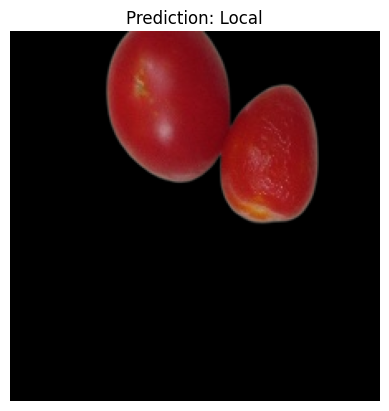

In [6]:
# Test a prediction
import glob
test_images = glob.glob(os.path.join(output_folder, 'test', '*', '*.*'))
if test_images:
    sample_img = test_images[0]
    result = model.predict(sample_img)
    
    # Display the image and predicted class
    img = cv2.imread(sample_img)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img)
    
    names_dict = result[0].names
    probs = result[0].probs.data.tolist()
    pred_class = names_dict[np.argmax(probs)]
    
    plt.title(f"Prediction: {pred_class}")
    plt.axis('off')
    plt.show()

In [ ]:
import shutil
import os

# Export the best model weights to a specific directory
models_dir = "/kaggle/working/models"
os.makedirs(models_dir, exist_ok=True)

# Because we explicitly set project="Tomato_Quality" and name="yolov8s_cls",
# YOLO saves the weights in that specific directory.
best_weights = 'runs/classify/Tomato_Quality/yolov8s_cls/weights/best.pt'

if os.path.exists(best_weights):
    shutil.copy(best_weights, os.path.join(models_dir, 'Tomato_grading_YOLO_BEST.pt'))
    print("Model saved to:", os.path.join(models_dir, 'Tomato_grading_YOLO_BEST.pt'))
else:
    print("Best weights not found. Check YOLO training output for run directory.")

Model saved to: /kaggle/working/models/Tomato_grading_YOLO_BEST.pt
